# 转置卷积
要保持输入和输出的空间维度（H和W）相同，使用转置卷积。对于**像素级**分类的语义分割很有用（pixel-pixel）

为了实现这一点，尤其是在空间维度被卷积神经网络层缩小后，我们可以使用另一种类型的卷积神经网络层，它可以增加**上采样**中间层特征图的空间维度。

上采样就是小特征图变回大尺寸特征图，相当于还原原图的分辨率，是逆下采样过程

![卷积核为 $2\times 2$ 的转置卷积。阴影部分是中间张量的一部分，也是用于计算的输入和卷积核张量元素。 ](../李沐《动手学深度学习》\d2l-zh\pytorch\img\trans_conv.svg)

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l
# X是输入张量，K是卷积核
def transposed_conv(X, K):
    h, w = K.shape
    Y = torch.zeros(size = (X.shape[0] + h - 1, X.shape[1] + w - 1))
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Y[i : i + h, j : j + w] += X[i, j] * K
    return Y

In [2]:
X = torch.tensor([[0.0, 1.0], [2.0, 3.0]])
K = torch.tensor([[0.0, 1.0], [2.0, 3.0]])
transposed_conv(X, K)

tensor([[ 0.,  0.,  1.],
        [ 0.,  4.,  6.],
        [ 4., 12.,  9.]])

或者，当输入`X`和卷积核`K`都是四维张量时，我们可以[**使用高级API获得相同的结果**]。`

In [3]:
X, K = X.reshape(1, 1, 2, 2), K.reshape(1, 1, 2, 2)
transconv = nn.ConvTranspose2d(in_channels = 1, out_channels = 1, kernel_size = 2, stride = 1, bias = False)
transconv.weight.data = K
transconv(X)

tensor([[[[ 0.,  0.,  1.],
          [ 0.,  4.,  6.],
          [ 4., 12.,  9.]]]], grad_fn=<ConvolutionBackward0>)

与常规卷积不同，在转置卷积中，填充被应用于的输出（常规卷积将填充应用于输入）。
例如，当将高和宽两侧的填充数指定为1时，转置卷积的输出中将删除第一和最后的行与列。

In [4]:
transconv = nn.ConvTranspose2d(1, 1, 2, padding = 1, bias = False)
transconv.weight.data = K
transconv(X)

tensor([[[[4.]]]], grad_fn=<ConvolutionBackward0>)

在转置卷积中，步幅被指定为中间结果（输出），而不是输入。
使用 :numref:`fig_trans_conv`中相同输入和卷积核张量，将步幅从1更改为2会增加中间张量的高和权重，因此输出张量在 :numref:`fig_trans_conv_stride2`中。

![卷积核为$2\times 2$，步幅为2的转置卷积。阴影部分是中间张量的一部分，也是用于计算的输入和卷积核张量元素。](../李沐《动手学深度学习》\d2l-zh\pytorch\img\trans_conv_stride2.svg)
:label:`fig_trans_conv_stride2`

以下代码可以验证 :numref:`fig_trans_conv_stride2`中步幅为2的转置卷积的输出。

In [5]:
tconv = nn.ConvTranspose2d(1, 1, kernel_size=2, stride=2, bias=False)
tconv.weight.data = K
tconv(X)

tensor([[[[0., 0., 0., 1.],
          [0., 0., 2., 3.],
          [0., 2., 0., 3.],
          [4., 6., 6., 9.]]]], grad_fn=<ConvolutionBackward0>)

In [6]:
X = torch.rand(size=(1, 10, 16, 16))
conv = nn.Conv2d(10, 20, kernel_size=5, padding=2, stride=3)
tconv = nn.ConvTranspose2d(20, 10, kernel_size=5, padding=2, stride=3)
print(tconv(conv(X)).shape == X.shape)
print(conv(X).shape)

True
torch.Size([1, 20, 6, 6])


# 全卷积网络
全卷积网络先使用卷积神经网络提取图像特征，然后通过1 $\times $ 1卷积层将通道数变为类别个数，最后再通过转置卷积层将图像变换为原尺寸

![全卷积网络](../李沐《动手学深度学习》\d2l-zh\pytorch\img\fcn.svg)

下面，我们[**使用在ImageNet数据集上预训练的ResNet-18模型来提取图像特征**]，并将该网络记为`pretrained_net`。
ResNet-18模型的最后几层包括全局平均汇聚层和全连接层，然而全卷积网络中不需要它们。

In [7]:
%matplotlib inline
import torchvision
# import os
# import ssl
# 清除残留代理环境变量
# os.environ.pop("HTTP_PROXY", None)
# os.environ.pop("HTTPS_PROXY", None)
pretrained_net = torchvision.models.resnet18(weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
list(pretrained_net.children())[-3:]

[Sequential(
   (0): BasicBlock(
     (conv1): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
     (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (relu): ReLU(inplace=True)
     (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (downsample): Sequential(
       (0): Conv2d(256, 512, kernel_size=(1, 1), stride=(2, 2), bias=False)
       (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     )
   )
   (1): BasicBlock(
     (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (relu): ReLU(inplace=True)
     (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn2): Batc

IMAGENET1K_V1
* ImageNet‑1K：一个大型图像数据集，一共 **1000 个图像类别**
* V1：第 1 版预训练权重，`V1`代表**权重文件的版本号**



- `.children()`：只看**直接子层**，不拆 Sequential 内部。
- `.modules()`：递归遍历**所有嵌套模块**，深度优先，会把 Sequential 里面的 Conv、BN 全部拿出来。

接下来，我们[**创建一个全卷积网络`net`**]。
它复制了ResNet-18中大部分的预训练层，除了最后的全局平均汇聚层和最接近输出的全连接层。

In [8]:
net = nn.Sequential(*list(pretrained_net.children())[:-2])

给定高度为320和宽度为480的输入，`net`的前向传播将输入的高和宽减小至原来的$1/32$，即10和15。

In [9]:
X = torch.rand(size=(1, 3, 320, 480))
net(X).shape

torch.Size([1, 512, 10, 15])

接下来[**使用$1\times1$卷积层将输出通道数转换为Pascal VOC2012数据集的类数（21类）。**]
最后需要(**将特征图的高度和宽度增加32倍**)，从而将其变回输入图像的高和宽。
回想一下 :numref:`sec_padding`中卷积层输出形状的计算方法：
由于$(320-64+16\times2+32)/32=10$且$(480-64+16\times2+32)/32=15$，我们构造一个步幅为$32$的转置卷积层，并将卷积核的高和宽设为$64$，填充为$16$。
我们可以看到如果步幅为$s$，填充为$s/2$（假设$s/2$是整数）且卷积核的高和宽为$2s$，转置卷积核会将输入的高和宽分别放大$s$倍。

In [10]:
num_classes = 21
net.add_module('final_conv', nn.Conv2d(512, num_classes, 1))
net.add_module('transposed_conv', nn.ConvTranspose2d(num_classes, num_classes, kernel_size = 64, stride = 32, padding = 16))

## [**初始化转置卷积层**]

在图像处理中，我们有时需要将图像放大，即*上采样*（upsampling）。
*双线性插值*（bilinear interpolation）
是常用的上采样方法之一，它也经常用于初始化转置卷积层。

为了解释双线性插值，假设给定输入图像，我们想要计算上采样输出图像上的每个像素。

1. 将输出图像的坐标$(x,y)$映射到输入图像的坐标$(x',y')$上。
例如，根据输入与输出的尺寸之比来映射。
请注意，映射后的$x′$和$y′$是实数。
2. 在输入图像上找到离坐标$(x',y')$最近的4个像素。
3. 输出图像在坐标$(x,y)$上的像素依据输入图像上这4个像素及其与$(x',y')$的相对距离来计算。

双线性插值的上采样可以通过转置卷积层实现，内核由以下`bilinear_kernel`函数构造。
限于篇幅，我们只给出`bilinear_kernel`函数的实现，不讨论算法的原理。

In [11]:
def bilinear_kernel(in_channels, out_channels, kernel_size):
    # factor:放大倍数
    factor = (kernel_size + 1) // 2
    if kernel_size % 2 == 1:
        # 奇数核
        center = factor - 1
    else:
        # 偶数核
        center = factor - 0.5
    og = (torch.arange(kernel_size).reshape(-1, 1),
          torch.arange(kernel_size).reshape(1, -1)) # og.size = ((kernel_size, 1), (1, kernel_size))
    filt = (1 - torch.abs(og[0] - center) / factor) * \
           (1 - torch.abs(og[1] - center) / factor) # 用1减去[0,1]之间的一个数是为了让越靠近中心的权重越大
    weight = torch.zeros((in_channels, out_channels,
                          kernel_size, kernel_size))
    weight[range(in_channels), range(out_channels), :, :] = filt
    return weight

```
weight[ i , i , : , : ] = filt
```

> 只在**对角通道**赋值这个双线性核。

- 输入第`i`通道，只输出到输出第`i`通道，使用双线性核；
- **不同通道之间不发生混合**。

让我们用[**双线性插值的上采样实验**]它由转置卷积层实现。
我们构造一个将输入的高和宽放大2倍的转置卷积层，并将其卷积核用`bilinear_kernel`函数初始化。

In [27]:
conv_trans = nn.ConvTranspose2d(3, 3, 4, stride = 2, padding = 1, bias = False)
conv_trans.weight.data.copy_(bilinear_kernel(3, 3, 4));

读取图像`X`，将上采样的结果记作`Y`。为了打印图像，我们需要调整通道维的位置。

In [28]:
img = torchvision.transforms.ToTensor()(d2l.Image.open('../李沐《动手学深度学习》\d2l-zh\pytorch\img\catdog.jpg')) # 变成张量格式并且归一化
X = img.unsqueeze(0) # 增加batch维
Y = conv_trans(X)
out_img = Y[0].permute(1, 2, 0).detach() # [H, W, C]（matplotlib画图需要）,关闭计算图，不跟踪梯度

input image shape: torch.Size([561, 728, 3])
output image shape: torch.Size([1122, 1456, 3])


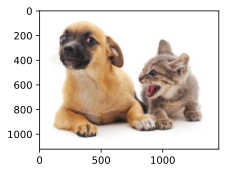

In [29]:
d2l.set_figsize()
print('input image shape:', img.permute(1, 2, 0).shape)
d2l.plt.imshow(img.permute(1, 2, 0));
print('output image shape:', out_img.shape)
d2l.plt.imshow(out_img);

全卷积网络[**用双线性插值的上采样初始化转置卷积层。对于$1\times 1$卷积层，我们使用Xavier初始化参数。**]

In [30]:
W = bilinear_kernel(num_classes, num_classes, 64)
net.transposed_conv.weight.data.copy_(W);

## [**读取数据集**]

我们用 :numref:`sec_semantic_segmentation`中介绍的语义分割读取数据集。
指定随机裁剪的输出图像的形状为$320\times 480$：高和宽都可以被$32$整除。


In [31]:
batch_size, crop_size = 32, (320, 480)
train_iter, test_iter = d2l.load_data_voc(batch_size, crop_size)

read 1114 examples
read 1078 examples


## [**训练**]

现在我们可以训练全卷积网络了。
这里的损失函数和准确率计算与图像分类中的并没有本质上的不同，因为我们使用转置卷积层的通道来预测像素的类别，所以需要在损失计算中指定通道维。
此外，模型基于每个像素的预测类别是否正确来计算准确率。

loss 0.411, train acc 0.870, test acc 0.852
10.0 examples/sec on [device(type='cuda', index=0)]


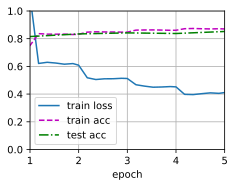

In [32]:
def loss(inputs, targets):
    return F.cross_entropy(inputs, targets, reduction='none').mean(1).mean(1)
num_epochs, lr, wd, devices = 5, 0.001, 1e-3, d2l.try_all_gpus()
trainer = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=wd)
d2l.train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs, devices)

## [**预测**]

在预测时，我们需要将输入图像在各个通道做标准化，并转成卷积神经网络所需要的四维输入格式。

In [33]:
def predict(img):
    X = test_iter.dataset.normalize_image(img).unsqueeze(0)
    pred = net(X.to(devices[0])).argmax(dim=1)
    return pred.reshape(pred.shape[1], pred.shape[2])

为了[**可视化预测的类别**]给每个像素，我们将预测类别映射回它们在数据集中的标注颜色。

In [34]:
def label2image(pred):
    colormap = torch.tensor(d2l.VOC_COLORMAP, device=devices[0])
    X = pred.long()
    return colormap[X, :]

测试数据集中的图像大小和形状各异。
由于模型使用了步幅为32的转置卷积层，因此当输入图像的高或宽无法被32整除时，转置卷积层输出的高或宽会与输入图像的尺寸有偏差。
为了解决这个问题，我们可以在图像中截取多块高和宽为32的整数倍的矩形区域，并分别对这些区域中的像素做前向传播。
请注意，这些区域的并集需要完整覆盖输入图像。
当一个像素被多个区域所覆盖时，它在不同区域前向传播中转置卷积层输出的平均值可以作为`softmax`运算的输入，从而预测类别。

为简单起见，我们只读取几张较大的测试图像，并从图像的左上角开始截取形状为$320\times480$的区域用于预测。
对于这些测试图像，我们逐一打印它们截取的区域，再打印预测结果，最后打印标注的类别。

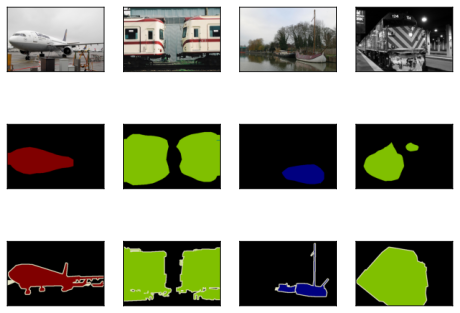

In [35]:
voc_dir = d2l.download_extract('voc2012', 'VOCdevkit/VOC2012')
test_images, test_labels = d2l.read_voc_images(voc_dir, False)
n, imgs = 4, []
for i in range(n):
    crop_rect = (0, 0, 320, 480)
    X = torchvision.transforms.functional.crop(test_images[i], *crop_rect)
    pred = label2image(predict(X))
    imgs += [X.permute(1,2,0), pred.cpu(),
             torchvision.transforms.functional.crop(
                 test_labels[i], *crop_rect).permute(1,2,0)]
d2l.show_images(imgs[::3] + imgs[1::3] + imgs[2::3], 3, n, scale=2);